# Volatility: returns, conditional variance, and uncertainty about variance

A volatility forecast can describe three different quantities: the next return, its conditional variance, and the uncertainty in that future variance. This notebook keeps them separate using generated data with observable ground truth. We fit return models through Convexity, compare their variance forecasts, then model a realized-variance series with HAR.

All quantities use the input time step. Returns are in arbitrary units; variance is in squared units per observation. Model parameters are estimated from training data only. Predictive uncertainty below is conditional on fitted parameters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import volatility as vol

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## A known GARCH process gives us something to inspect

Generate $r_t=\sqrt{h_t}z_t$ with $h_t=\omega+\alpha r_{t-1}^2+\beta h_{t-1}$. The standardized Student-t innovations have variance one. With $\alpha+\beta<1$, the unconditional return variance is $\omega/(1-\alpha-\beta)$.

Discard a burn-in, reserve the last 250 observations, and estimate the same model family. Finite-sample estimates need not equal the generating parameters; the latent variance curve is a more informative comparison than a success assertion.

In [2]:
omega, alpha, beta, degrees = .02, .08, .86, 6.
n = 1400
innovation = vol.innovation_distribution("student_t", (degrees,)).sample(n, rng=rng)
returns, true_variance = np.empty(n), np.empty(n)
true_variance[0] = omega/(1-alpha-beta)
returns[0] = np.sqrt(true_variance[0])*innovation[0]
for t in range(1, n):
    true_variance[t] = omega + alpha*returns[t-1]**2 + beta*true_variance[t-1]
    returns[t] = np.sqrt(true_variance[t])*innovation[t]
returns, true_variance = returns[250:], true_variance[250:]
cutoff = 900
fitted = vol.GARCHForecaster(mean="zero", innovation="student_t").fit(returns[:cutoff])
truth = pd.Series({"omega": omega, "alpha[1]": alpha, "beta[1]": beta, "nu": degrees})
pd.DataFrame({"generating parameter": truth, "estimated": pd.Series(fitted.parameters["coefficients"])})

,generating parameter,estimated
omega,0.02,0.029442
alpha[1],0.08,0.094341
beta[1],0.86,0.817391
nu,6.00,4.925277


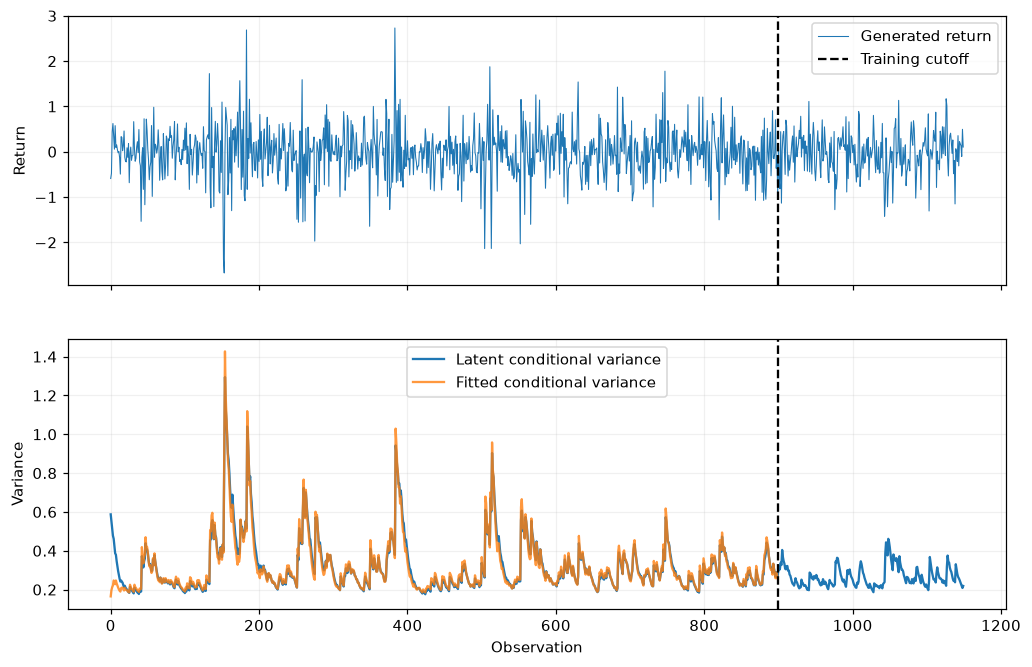

In [3]:
estimated_variance = np.asarray(fitted.parameters["conditional_volatility"])**2
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(returns, lw=.7, label="Generated return")
axes[0].axvline(cutoff, color="k", ls="--", label="Training cutoff")
axes[0].set(ylabel="Return")
axes[0].legend()
axes[1].plot(true_variance, label="Latent conditional variance")
axes[1].plot(np.arange(cutoff), estimated_variance, alpha=.8, label="Fitted conditional variance")
axes[1].axvline(cutoff, color="k", ls="--")
axes[1].set(xlabel="Observation", ylabel="Variance")
axes[1].legend()
plt.show()

## Expected future variance is not a future variance path

For this generator, the first future variance is determined by the last return and variance. Subsequent *expected* variances revert geometrically toward the long-run level. Compare that oracle conditional expectation with the fitted analytic forecast.

Simulation draws future shocks and propagates each variance path. The shaded interval describes uncertainty about future **conditional variance**. It is neither a return interval nor an interval for squared observed returns. Its first step collapses because that variance is already determined under the fitted model.

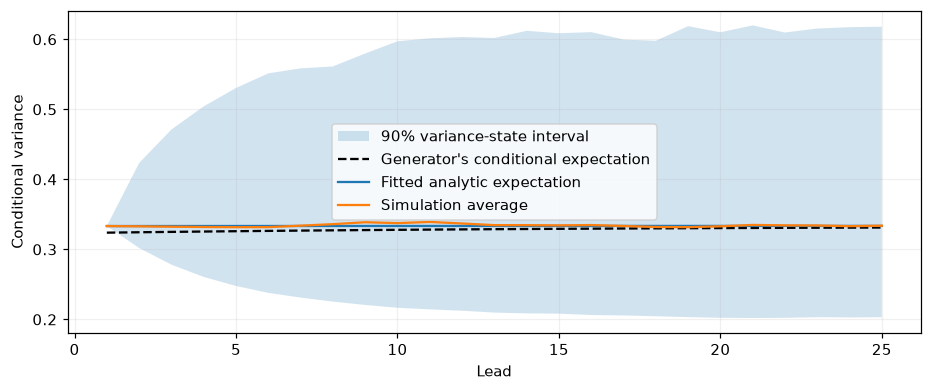

,lead,sqrt(E[variance]),E[sqrt(variance)],simulated return variance
0,1,0.577335,0.577335,0.328911
1,5,0.575940,0.569237,0.330913
2,25,0.577750,0.563049,0.332621


In [4]:
leads = np.arange(1, 26)
analytic = fitted.forecast(25)
simulated = vol.GARCHForecaster(mean="zero", innovation="student_t", method="simulation", simulations=6000).fit(
    returns[:cutoff]).forecast(25, rng=np.random.default_rng(9))
variance_band = simulated.variance_forecast().interval(.9)[:, 0]
long_run = omega/(1-alpha-beta)
next_variance = omega+alpha*returns[cutoff-1]**2+beta*true_variance[cutoff-1]
oracle = long_run+(alpha+beta)**(leads-1)*(next_variance-long_run)
fig, ax = plt.subplots()
ax.fill_between(leads, variance_band[:, 0], variance_band[:, 1], alpha=.2, label="90% variance-state interval")
ax.plot(leads, oracle, "k--", label="Generator's conditional expectation")
ax.plot(leads, analytic.conditional_variance[:, 0], label="Fitted analytic expectation")
ax.plot(leads, simulated.conditional_variance[:, 0], label="Simulation average")
ax.set(xlabel="Lead", ylabel="Conditional variance")
ax.legend()
plt.show()
pd.DataFrame({"lead": leads[[0, 4, 24]],
    "sqrt(E[variance])": simulated.volatility()[[0, 4, 24], 0],
    "E[sqrt(variance)]": np.sqrt(simulated.conditional_variance_paths).mean(axis=0)[[0, 4, 24], 0],
    "simulated return variance": simulated.variance()[[0, 4, 24], 0]})

Convexity's `volatility()` reports $\sqrt{E[h]}$. Jensen's inequality explains why it generally exceeds $E[\sqrt{h}]$. In this zero-mean model, return variance is also $E[h]$; Monte Carlo estimates fluctuate around that identity.

The one-step return law is a scaled Student-t. At longer leads, variance mixes over future paths, so simply multiplying a fixed Student-t quantile by forecast volatility would impose an unjustified marginal law. Use the simulated return distribution instead.

In [5]:
probabilities = [.01, .05, .5, .95, .99]
return_quantiles = {"one-step analytic": [fitted.forecast(1).quantile(p)[0, 0] for p in probabilities]}
for lead in (1, 5, 25):
    return_quantiles[f"lead {lead}, simulation"] = [simulated.quantile(p)[lead-1, 0] for p in probabilities]
pd.DataFrame(return_quantiles, index=pd.Index(probabilities, name="Quantile"))

,one-step analytic,"lead 1, simulation","lead 5, simulation","lead 25, simulation"
Quantile,,,,
0.01,-1.506717,-1.470097,-1.572381,-1.558138
0.05,-0.899577,-0.891821,-0.890632,-0.902043
0.50,0.000000,0.000949,0.004658,-0.001648
0.95,0.899577,0.942738,0.918850,0.881006
0.99,1.506717,1.526784,1.520978,1.503035


## Different variance dynamics under the same contract

Constant variance, EWMA, ARCH, GARCH, GJR-GARCH, and EGARCH all expose `conditional_variance`. The models differ in persistence, asymmetry, and how they extrapolate. Their defaults need not use the same forecasting algorithm; EGARCH uses simulation when an analytic multistep expression is unavailable.

This is a comparison on symmetric GARCH data, not evidence that the more flexible asymmetric specifications always improve forecasts. The table shows the behavior to investigate.

In [6]:
catalog = {
    "Constant": vol.ConstantVarianceForecaster(mean="zero"),
    "EWMA": vol.EWMAForecaster(mean="zero"),
    "ARCH(3)": vol.ARCHForecaster(3, mean="zero"),
    "GARCH": vol.GARCHForecaster(mean="zero"),
    "GJR-GARCH": vol.GJRGARCHForecaster(mean="zero"),
    "EGARCH": vol.EGARCHForecaster(mean="zero"),
}
pd.DataFrame({name: specification.fit(returns[:cutoff]).forecast([1, 5, 20], rng=np.random.default_rng(13)).conditional_variance[:, 0]
              for name, specification in catalog.items()}, index=pd.Index([1, 5, 20], name="Lead")).T

Lead,1,5,20
Constant,0.310988,0.310988,0.310988
EWMA,0.293258,0.293258,0.293258
ARCH(3),0.287497,0.332810,0.315554
GARCH,0.318409,0.317067,0.314670
GJR-GARCH,0.331006,0.324094,0.310120
EGARCH,0.338473,0.341483,0.343975


## Score the intended quantity and inspect what remains

A variance proxy enters evaluation only. Here the generator supplies the true conditional variance, avoiding the extra noise of squared returns. At each origin, the backtest refits using only earlier rows. Convexity uses QLIKE $\log(\hat v)+v/\hat v$, omitting terms that do not depend on the forecast. Smaller is better; the score can be negative.

Standardized residuals should have roughly unit variance and little remaining conditional heteroskedasticity. An ARCH LM p-value is one diagnostic, not a certificate of model adequacy.

In [7]:
scores = {}
for name in ("EWMA", "GARCH"):
    evaluation = vol.variance_backtest(catalog[name], returns[:cutoff], variance_proxy=true_variance[:cutoff],
        horizon=[1, 5], initial_window=600, step=50)
    scores[name] = evaluation.score(by_horizon=True).ravel()
display(pd.DataFrame(scores, index=pd.Index([1, 5], name="Lead / QLIKE")))
standardized = np.asarray(fitted.parameters["standardized_residuals"])
diagnostics = vol.volatility_diagnostics(standardized, lags=10)
pd.Series({"Residual mean": np.nanmean(standardized), "Residual variance": np.nanvar(standardized),
           "ARCH LM p-value": diagnostics["arch_lm_pvalue"][0]}).to_frame("Value")

,EWMA,GARCH
Lead / QLIKE,,
1,-0.263700,-0.272447
5,-0.235101,-0.243625


,Value
Residual mean,-0.044531
Residual variance,0.976402
ARCH LM p-value,0.448644


## HAR forecasts realized variance on a positive scale

Generate a latent log-variance process with daily, five-step, and 22-step averages. Sum 100 squared intraperiod returns to obtain a noisy realized-variance measurement. HAR fits that observed measurement, so its coefficients need not recover the latent generator exactly.

For log-HAR, future log variances are jointly Gaussian conditional on fitted coefficients. Exponentiation produces a **correlated lognormal path law**. The analytic forecast supplies its mean, covariance, samples, and exact marginal quantiles. Its mean exceeds its median; both are positive. These intervals include log-innovation uncertainty, but do not integrate over coefficient uncertainty.

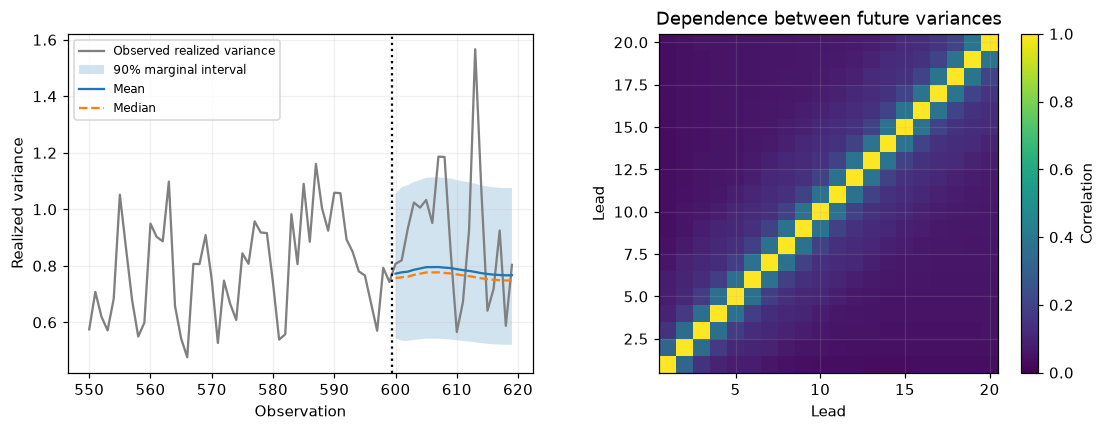

,Coefficient
constant,-0.099911
lag_mean_1,0.315045
lag_mean_5,0.126062
lag_mean_22,0.221264


In [8]:
log_variance = np.zeros(850)
for t in range(22, len(log_variance)):
    log_variance[t] = (-.05+.4*log_variance[t-1]+.25*log_variance[t-5:t].mean()
                      +.15*log_variance[t-22:t].mean()+rng.normal(scale=.15))
intraperiod = rng.normal(size=(850, 100))*np.sqrt(np.exp(log_variance[:, None])/100)
realized = vol.realized_variance(intraperiod)[150:]
har = vol.HARForecaster(transform="log").fit(realized[:600])
har_forecast = har.forecast(20)
har_band = har_forecast.interval(.9)[:, 0]
future = np.arange(600, 620)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(550, 620), realized[550:620], color="gray", label="Observed realized variance")
axes[0].fill_between(future, har_band[:, 0], har_band[:, 1], alpha=.2, label="90% marginal interval")
axes[0].plot(future, har_forecast.mean()[:, 0], label="Mean")
axes[0].plot(future, har_forecast.quantile(.5)[:, 0], "--", label="Median")
axes[0].axvline(599.5, color="k", ls=":")
axes[0].set(xlabel="Observation", ylabel="Realized variance")
axes[0].legend(fontsize=8)
covariance = har_forecast.covariance()
correlation = covariance/np.sqrt(np.outer(np.diag(covariance), np.diag(covariance)))
im = axes[1].imshow(correlation, vmin=0, vmax=1, origin="lower", extent=(.5, 20.5, .5, 20.5))
axes[1].set(xlabel="Lead", ylabel="Lead", title="Dependence between future variances")
fig.colorbar(im, ax=axes[1], label="Correlation")
plt.show()
pd.DataFrame({"Coefficient": har.parameters["coefficients"]}, index=har.parameters["feature_names"])

Return models forecast the original return target; HAR forecasts realized variance. Use `variance_forecast()` when evaluation should target the variance quantity itself. Annualization, when appropriate to the sampling convention, is an explicit scaling choice and does not create a finer-time model. See the [volatility guide](../volatility_forecasting.md) for supported innovations, bootstrap forecasts, covariates, and model-specific restrictions.